In [31]:
import pandas as pd
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report,f1_score,confusion_matrix
from xgboost import XGBClassifier


In [32]:
df = pd.read_csv('loan_data.csv')

In [33]:
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [34]:
df['person_education'].value_counts()

person_education
Bachelor       13399
Associate      12028
High School    11972
Master          6980
Doctorate        621
Name: count, dtype: int64

In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  45000 non-n

In [36]:
df['loan_status'].value_counts()

loan_status
0    35000
1    10000
Name: count, dtype: int64

In [37]:
df['loan_status'].nunique()

2

In [38]:
X = df.drop(columns='loan_status')
y = df['loan_status']

In [39]:
xtrain, xtest, ytrain, ytest = train_test_split(X, y, train_size = 0.8, random_state=42)

In [40]:
num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(include='object').columns

C:\Users\Ragavi\AppData\Local\Temp\ipykernel_20228\2083285147.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns


In [41]:
num_cols

Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score'],
      dtype='str')

<Axes: >

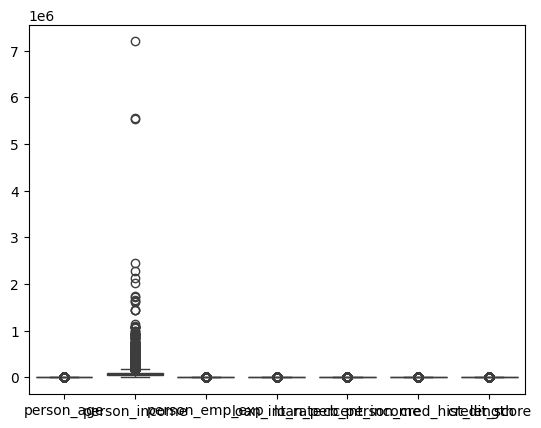

In [42]:
sns.boxplot(df[num_cols.drop( 'loan_amnt','loan_percent_income')])

In [43]:
preprocessing = ColumnTransformer(
    transformers=[
        ('scaling',RobustScaler(),num_cols),
        ('encoding',OneHotEncoder(handle_unknown='ignore',sparse_output=True),cat_cols)
    ],
    remainder='passthrough'
)

In [44]:

main_pipeline = Pipeline(
    steps=[
        ('pre', preprocessing),
        ('model', XGBClassifier(
            n_estimators=100,
            learning_rate=0.1,
            subsample=0.8,
            max_depth=10,
            colsample_bytree=0.8,
            eval_metric='logloss',
            random_state=42
        ))
    ]
)

main_pipeline.fit(xtrain, ytrain)

ytrain_pred = main_pipeline.predict(xtrain)
ytest_pred = main_pipeline.predict(xtest)

print("Training results:")
print(classification_report(ytrain, ytrain_pred))

print("Testing results:")
print(classification_report(ytest, ytest_pred))

print("Test F1-score for default class (1):",
      f1_score(ytest, ytest_pred, pos_label=1))

print("Confusion matrix:")
print(confusion_matrix(ytest, ytest_pred))

# Save the complete fitted pipeline
joblib.dump(main_pipeline, "loan_model.pkl")

print("Saved model as loan_model.pkl")


Training results:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     28010
           1       0.98      0.90      0.93      7990

    accuracy                           0.97     36000
   macro avg       0.97      0.94      0.96     36000
weighted avg       0.97      0.97      0.97     36000

Testing results:
              precision    recall  f1-score   support

           0       0.94      0.97      0.96      6990
           1       0.89      0.80      0.84      2010

    accuracy                           0.93      9000
   macro avg       0.92      0.88      0.90      9000
weighted avg       0.93      0.93      0.93      9000

Test F1-score for default class (1): 0.841057868551977
Confusion matrix:
[[6787  203]
 [ 404 1606]]
Saved model as loan_model.pkl


In [45]:
for col in cat_cols:
    print(col, df[col].unique())

person_gender <StringArray>
['female', 'male']
Length: 2, dtype: str
person_education <StringArray>
['Master', 'High School', 'Bachelor', 'Associate', 'Doctorate']
Length: 5, dtype: str
person_home_ownership <StringArray>
['RENT', 'OWN', 'MORTGAGE', 'OTHER']
Length: 4, dtype: str
loan_intent <StringArray>
[         'PERSONAL',         'EDUCATION',           'MEDICAL',
           'VENTURE',   'HOMEIMPROVEMENT', 'DEBTCONSOLIDATION']
Length: 6, dtype: str
previous_loan_defaults_on_file <StringArray>
['No', 'Yes']
Length: 2, dtype: str
